# Tutorial 2 — Vectorizadores de texto en scikit-learn

En la clase 2 representamos cinco sinopsis de películas de tres formas: conteos de palabras (bolsa de palabras), pesos TF-IDF y coordenadas LSA. BoW y TF-IDF se calcularon a mano sobre esas cinco sinopsis; LSA necesita un catálogo grande, y sus números en la clase salen de este tutorial. En este tutorial repetimos las tres representaciones con scikit-learn, ajustadas sobre las sinopsis de 20.559 películas de la Wikipedia en español, y las aplicamos a las cinco sinopsis de la clase para comparar el resultado con la tabla final de la diapositiva.

**Objetivos**

- Cargar un corpus y repasar su vocabulario con las herramientas de la clase 1.
- Construir matrices BoW, TF-IDF y LSA con `CountVectorizer`, `TfidfVectorizer` y `TruncatedSVD`, y conocer los argumentos de cada uno.
- Representar textos nuevos con un vectorizador ya ajustado y compararlos con la similitud coseno.

## 0. Preparación

En Colab ya están instalados pandas, scikit-learn, matplotlib, wordcloud y spaCy. La celda siguiente instala los que falten en una instalación local.

In [1]:
%%capture
%pip install -q wordcloud spacy

In [2]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from spacy.lang.es.stop_words import STOP_WORDS
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", None)

STOPWORDS = sorted(STOP_WORDS)  # lista de spaCy, como en la clase 1

Los datos vienen del volcado de la Wikipedia en español de noviembre de 2023 (`wikimedia/wikipedia`, configuración `20231101.es`). El archivo tiene una fila por película, con su título, año, géneros, la sección «Argumento», «Sinopsis» o «Trama» del artículo (columna `argumento`). El texto de Wikipedia se distribuye bajo la licencia CC BY-SA 4.0.

In [3]:
ARCHIVO = "https://raw.githubusercontent.com/dccuchile/CC66Q/main/tutorials/data/peliculas_wikipedia.csv.gz"

peliculas = pd.read_csv(ARCHIVO)
peliculas.shape

(29762, 4)

## 1. El corpus

No todos los artículos tienen una sección de argumento. Nos quedamos con los que la tienen, y esa sección es el documento.

In [4]:
corpus = peliculas.dropna(subset=["argumento"]).reset_index(drop=True)
textos = corpus["argumento"].tolist()
len(textos)

20559

In [5]:
corpus[["titulo", "anio", "generos"]].sample(5, random_state=0)

,titulo,anio,generos
14756,Clara es el precio,1975.0,NaN
18999,Sirena,NaN,NaN
18893,The Kid Brother,1927.0,comedia|romance|drama
8541,Tabou,2010.0,NaN
9602,Sube y baja,1959.0,comedia


In [6]:
print(corpus.loc[0, "titulo"])
print(textos[0][:500])

Blade Runner
En la ciudad de Los Ángeles, en noviembre de 2019, un blade runner excesivamente confiado —Dave Holden— recibe un tiro mientras llevaba a cabo el test Voight-Kampff a Leon Kowalski, un replicante fugitivo en la Tierra. Un antiguo blade runner, Rick Deckard, se encuentra en «The White Dragon Noodle Bar» de Howie Lee, el Maestro del Sushi, cuando es localizado por Gaff. Este le indica que el capitán Harry Bryant, su antiguo jefe, quiere verle. Dubitativo, se encuentra con Bryant, quien le informa 


In [7]:
corpus["argumento"].str.split().str.len().describe().round()

count    20559.0
mean       289.0
std        380.0
min         40.0
25%         73.0
50%        125.0
75%        356.0
max       6474.0
Name: argumento, dtype: float64

### 1.1 Frecuencias de palabras

El tokenizador de la clase 1: una expresión regular que separa palabras de dos o más caracteres, en minúsculas.

In [8]:
def tokenizar(texto: str) -> list[str]:
    """Devuelve las palabras de dos o más caracteres, en minúsculas."""
    return re.findall(r"\w\w+", texto.lower())


tokenizar(textos[0])[:12]

['en',
 'la',
 'ciudad',
 'de',
 'los',
 'ángeles',
 'en',
 'noviembre',
 'de',
 '2019',
 'un',
 'blade']

In [9]:
frecuencias = Counter()
for texto in textos:
    frecuencias.update(tokenizar(texto))

len(frecuencias), frecuencias.most_common(10)

(110665,
 [('de', 342044),
  ('la', 219456),
  ('que', 190398),
  ('el', 153033),
  ('en', 144850),
  ('su', 116075),
  ('un', 99970),
  ('se', 98505),
  ('una', 79101),
  ('los', 75596)])

Las palabras más frecuentes son funcionales: *de*, *la*, *que*. Las quitamos con la lista de stopwords de spaCy antes de graficar.

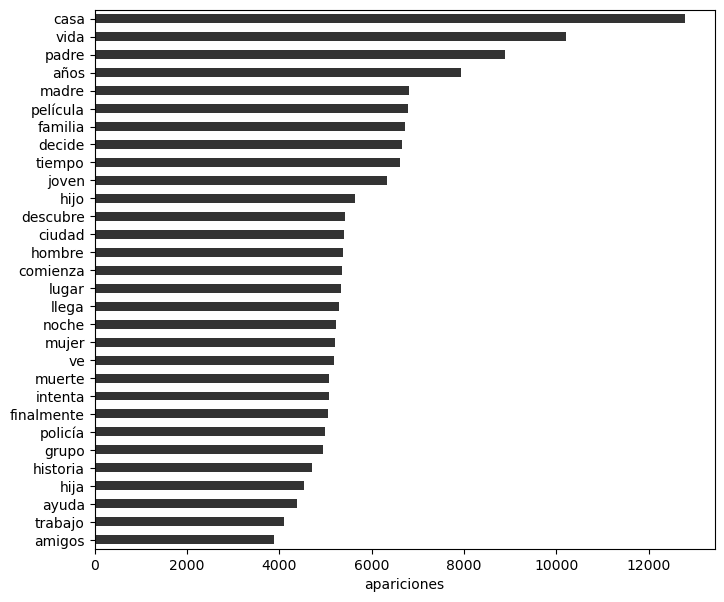

In [10]:
contenido = Counter({palabra: n for palabra, n in frecuencias.items()
                     if palabra not in STOP_WORDS})
top = pd.Series(dict(contenido.most_common(30)))
ax = top[::-1].plot.barh(figsize=(8, 7), color="#333333", xlabel="apariciones")

### 1.2 Nubes de palabras

Una nube por género, con las sinopsis de las películas de ciencia ficción y de las de wéstern.

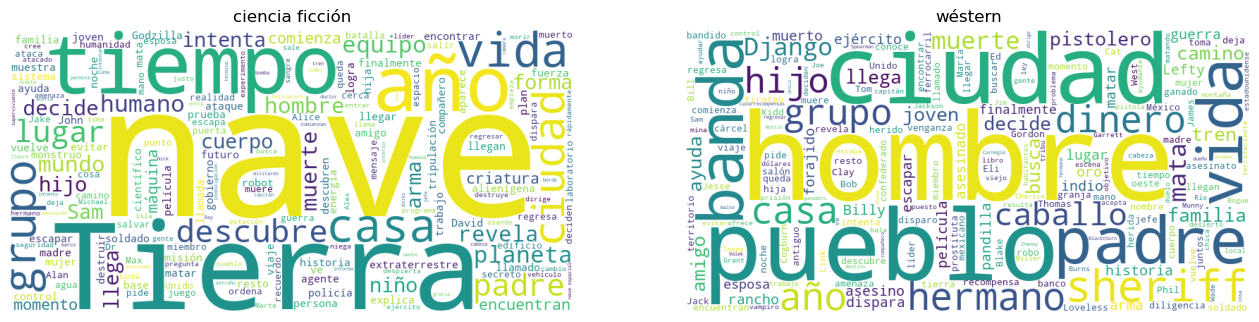

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 4))
for ax, genero in zip(ejes, ["ciencia ficción", "wéstern"]):
    filas = corpus["generos"].str.contains(genero, na=False)
    texto = " ".join(corpus.loc[filas, "argumento"])
    nube = WordCloud(width=800, height=400, background_color="white",
                     stopwords=STOP_WORDS, random_state=0).generate(texto)
    ax.imshow(nube)
    ax.set_title(genero)
    ax.axis("off")

## 2. Las cinco sinopsis de la clase

Las mismas cinco sinopsis de la diapositiva. Órbita es la referencia y las otras cuatro se comparan con ella.

In [12]:
sinopsis = pd.Series({
    "Órbita": (
        "Una astronauta viaja al espacio durante un año para estudiar la "
        "química de una estrella cercana. A esa distancia pierde el "
        "contacto con la base, y la atracción de la estrella empieza a "
        "sacar su cápsula de órbita. Sin señal, debe buscar la forma de "
        "volver."
    ),
    "Deriva": (
        "Un astronauta analiza la química de un cometa desde una cápsula "
        "en órbita. Cuando una tormenta daña la antena, la señal se corta "
        "y el módulo queda a la deriva en el espacio."
    ),
    "Masa madre": (
        "Dos hermanas heredan la panadería de su madre. Entre deudas y "
        "recetas antiguas, intentan salvarla y descubren secretos que "
        "cambian lo que creían saber de ella."
    ),
    "La casa del sur": (
        "Un año después de la muerte de su padre, Marta viaja al pueblo "
        "donde creció para vender la casa. Pierde el contacto con la "
        "ciudad y empieza a dudar. Cuando encuentra una carta de su madre, "
        "debe buscar la forma de volver."
    ),
    "Destino Kepler": (
        "Tras décadas a bordo de una nave que viaja rumbo a otro planeta, "
        "la tripulación despierta del sueño criogénico y descubre que el "
        "piloto automático cambió el destino. Cada año de desvío cuenta, "
        "y empieza una carrera para buscar la forma de volver a la ruta."
    ),
})
titulos = list(sinopsis.index)
sinopsis

Órbita              Una astronauta viaja al espacio durante un año para estudiar la química de una estrella cercana. A esa distancia pierde el contacto con la base, y la atracción de la estrella empieza a sacar su cápsula de órbita. Sin señal, debe buscar la forma de volver.
Deriva                                                                                                Un astronauta analiza la química de un cometa desde una cápsula en órbita. Cuando una tormenta daña la antena, la señal se corta y el módulo queda a la deriva en el espacio.
Masa madre                                                                                                          Dos hermanas heredan la panadería de su madre. Entre deudas y recetas antiguas, intentan salvarla y descubren secretos que cambian lo que creían saber de ella.
La casa del sur                                        Un año después de la muerte de su padre, Marta viaja al pueblo donde creció para vender la casa. Pierde el contacto c

## 3. Bolsa de palabras con CountVectorizer

Un vectorizador de scikit-learn trabaja en dos pasos. `fit` recorre el corpus y arma el vocabulario: una columna por palabra. `transform` recibe textos y devuelve la matriz, con una fila por texto. Los argumentos se fijan al crear el vectorizador. Abajo están los principales, con su valor por defecto salvo `stop_words`.

scikit-learn solo trae una lista de stopwords para inglés. Sin lista, *de*, *la* y *que* entran al vocabulario y dominan el coseno: Masa madre, que no comparte ninguna palabra de contenido con Órbita, queda en 0,30 en vez de 0. Usamos la lista de spaCy, como en la clase.

Guía de usuario: [The Bag of Words representation](https://scikit-learn.org/stable/modules/feature_extraction.html#the-bag-of-words-representation).

In [13]:
bow = CountVectorizer(
    strip_accents=None,      # None, "ascii" o "unicode": quita tildes
    lowercase=True,          # pasa a minúsculas antes de tokenizar
    stop_words=STOPWORDS,    # None, "english" o una lista propia
    token_pattern=r"(?u)\b\w\w+\b",  # regex: palabras de 2+ caracteres
    ngram_range=(1, 1),      # (1, 2): unigramas y bigramas
    max_df=1.0,              # ignora palabras en más de esta fracción
    min_df=1,                # ignora palabras en menos de este número
    max_features=None,       # conserva solo las N más frecuentes
    binary=False,            # True: 1 si aparece, 0 si no
)

In [14]:
bow.fit(textos)
len(bow.vocabulary_)

110191

`fit` solo aprendió el vocabulario: 110.191 palabras distintas, después de quitar las stopwords. `token_pattern` es la misma expresión regular de `tokenizar`. Los conteos se calculan al transformar.

In [15]:
X_wiki_bow = bow.transform(textos)
X_wiki_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1937587 stored elements and shape (20559, 110191)>

In [16]:
# % of non zeroes
X_wiki_bow.nnz / np.prod(X_wiki_bow.shape)

np.float64(0.0008552894224647632)

La matriz tiene 20.559 × 110.191 ≈ 2.265 millones de celdas y 1,9 millones distintas de cero: el 0,09 %. scipy guarda solo las celdas distintas de cero (formato CSR), y por eso cabe en memoria.

Las cinco sinopsis de la clase se transforman con el mismo vectorizador. Las columnas son las 110.191 del vocabulario de Wikipedia; mostramos solo las de las palabras de Órbita.

In [17]:
X_bow = bow.transform(sinopsis)
X_bow.shape

(5, 110191)

In [18]:
tabla = pd.DataFrame(X_bow.toarray(), index=titulos,
                     columns=bow.get_feature_names_out())
tabla.loc[:, tabla.loc["Órbita"] > 0]

,astronauta,atracción,año,base,buscar,cercana,contacto,cápsula,distancia,empieza,...,estrella,estudiar,forma,pierde,química,sacar,señal,viaja,volver,órbita
Órbita,1,1,1,1,1,1,1,1,1,1,...,2,1,1,1,1,1,1,1,1,1
Deriva,1,0,0,0,0,0,0,1,0,0,...,0,0,0,0,1,0,1,0,0,1
Masa madre,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
La casa del sur,0,0,1,0,1,0,1,0,0,1,...,0,0,1,1,0,0,0,1,1,0
Destino Kepler,0,0,1,0,1,0,0,0,0,1,...,0,0,1,0,0,0,0,1,1,0


In [19]:
sim_bow = pd.Series(cosine_similarity(X_bow)[0], index=titulos)
sim_bow

Órbita             1.00
Deriva             0.32
Masa madre         0.00
La casa del sur    0.37
Destino Kepler     0.26
dtype: float64

Deriva 0,32, Masa madre 0, La casa del sur 0,37, Destino Kepler 0,26. Son los conteos de la clase: La casa del sur queda primera porque comparte ocho palabras con Órbita, y Deriva seis.

## 4. TF-IDF con TfidfVectorizer

`TfidfVectorizer` tiene los mismos argumentos que `CountVectorizer` y cuatro más, que controlan el peso. Abajo dejamos solo `stop_words` y esos cuatro; el resto queda con su valor por defecto, igual que en la bolsa de palabras. Su fórmula es una variante de la de la clase 1:

$$\mathrm{idf}(t) = \ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1$$

y después normaliza cada fila para que tenga largo 1 (`norm="l2"`), así que el coseno entre dos filas es su producto punto.

Guía de usuario: [Tf–idf term weighting](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting).

In [20]:
tfidf = TfidfVectorizer(
    stop_words=STOPWORDS,    # None, "english" o una lista propia
    norm="l2",               # "l2", "l1" o None: normaliza cada fila
    use_idf=True,            # False: solo tf
    smooth_idf=True,         # suma 1 a N y a df (la fórmula de arriba)
    sublinear_tf=False,      # True: 1 + log(tf) en vez de tf
)

`fit` recorre el corpus y guarda, además del vocabulario, el idf de cada palabra (atributo `idf_`). Para ver el df, contamos en la matriz BoW en cuántas sinopsis aparece cada palabra.

In [21]:
tfidf.fit(textos)

palabras = ["astronauta", "cápsula", "nave", "año", "forma", "volver"]
pesos = pd.DataFrame({"df": (X_wiki_bow > 0).sum(axis=0).A1,
                      "idf": tfidf.idf_},
                     index=tfidf.get_feature_names_out())
pesos.loc[palabras]

,df,idf
astronauta,37,7.29
cápsula,79,6.55
nave,414,4.90
año,1299,3.76
forma,2079,3.29
volver,1517,3.61


*Astronauta* aparece en 37 sinopsis y pesa 7,29; *año* aparece en 1.299 y pesa 3,76. En la clase, con N = 5, los mismos pesos eran 0,40 y 0,22. El corpus de referencia ahora son las 20.559 sinopsis.

In [22]:
X_tfidf = tfidf.transform(sinopsis)
tabla = pd.DataFrame(X_tfidf.toarray(), index=titulos,
                     columns=tfidf.get_feature_names_out())
tabla.loc[:, tabla.loc["Órbita"] > 0]

,astronauta,atracción,año,base,buscar,cercana,contacto,cápsula,distancia,empieza,...,estrella,estudiar,forma,pierde,química,sacar,señal,viaja,volver,órbita
Órbita,0.3,0.22,0.15,0.19,0.15,0.21,0.18,0.27,0.22,0.15,...,0.36,0.22,0.14,0.17,0.27,0.2,0.22,0.17,0.15,0.27
Deriva,0.3,0.00,0.00,0.00,0.00,0.00,0.00,0.27,0.00,0.00,...,0.00,0.00,0.00,0.00,0.27,0.0,0.22,0.00,0.00,0.27
Masa madre,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
La casa del sur,0.0,0.00,0.20,0.00,0.20,0.00,0.24,0.00,0.00,0.19,...,0.00,0.00,0.18,0.23,0.00,0.0,0.00,0.23,0.20,0.00
Destino Kepler,0.0,0.00,0.15,0.00,0.15,0.00,0.00,0.00,0.00,0.14,...,0.00,0.00,0.13,0.00,0.00,0.0,0.00,0.17,0.14,0.00


In [23]:
sim_tfidf = pd.Series(cosine_similarity(X_tfidf)[0], index=titulos)
sim_tfidf

Órbita             1.00
Deriva             0.40
Masa madre         0.00
La casa del sur    0.27
Destino Kepler     0.14
dtype: float64

Deriva 0,40, Masa madre 0, La casa del sur 0,27, Destino Kepler 0,14. Los números no son los de la diapositiva (0,16, 0, 0,10 y 0,04), porque cambiaron la fórmula y el corpus de referencia. El orden sí: Deriva pasa a La casa del sur, cuyas ocho palabras en común con Órbita aparecen en miles de sinopsis y pesan poco.

## 5. LSA con TruncatedSVD

`TruncatedSVD` calcula la descomposición $X = U \Sigma V^\top$ de la matriz TF-IDF del corpus y conserva los $k$ valores singulares más grandes. `fit` guarda $V_k^\top$ (atributo `components_`, de $k \times n$). `transform` devuelve $X V_k$ (en código, `X @ svd.components_.T`), las filas de $U_k \Sigma_k$: cada documento con $k$ coordenadas en vez de 110.191. Para un texto nuevo $q$, `transform` devuelve $q V_k$, como en la clase.

Por defecto $k = 2$. Usamos $k = 100$, el rango que Deerwester et al. (1990) usaron en sus pruebas. El algoritmo es aleatorizado, así que fijamos `random_state` para obtener el mismo resultado en cada ejecución.

Guía de usuario: [Truncated singular value decomposition and latent semantic analysis](https://scikit-learn.org/stable/modules/decomposition.html#lsa).

In [24]:
svd = TruncatedSVD(
    n_components=100,        # k: dimensiones que se conservan
    algorithm="randomized",  # "randomized" o "arpack"
    n_iter=5,                # iteraciones del método aleatorizado
    random_state=0,          # semilla del método aleatorizado
)

In [25]:
X_wiki_tfidf = tfidf.transform(textos)
svd.fit(X_wiki_tfidf)
svd.components_.shape

(100, 110191)

In [26]:
X_lsa = svd.transform(X_tfidf)
pd.DataFrame(X_lsa, index=titulos)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
Órbita,0.07,-0.04,1.19e-02,0.01,-5.47e-03,1.77e-02,3.37e-02,-2.18e-02,1.78e-02,-0.03,...,-6.60e-03,-3.08e-03,-2.61e-03,-1.74e-02,4.69e-03,9.47e-03,-1.73e-02,4.83e-03,-1.63e-03,8.00e-04
Deriva,0.02,-0.03,1.84e-03,0.01,-3.12e-03,1.30e-02,1.75e-02,-1.55e-02,1.47e-03,-0.02,...,5.07e-03,-3.23e-03,1.00e-03,-4.74e-04,5.02e-03,2.64e-03,4.72e-03,3.61e-03,-1.01e-02,3.48e-03
Masa madre,0.04,0.01,-2.44e-02,0.02,-2.57e-02,1.16e-02,2.16e-03,5.71e-03,1.28e-03,-0.01,...,-1.63e-02,-1.78e-03,3.09e-03,2.42e-03,2.33e-03,-1.27e-02,8.77e-03,1.27e-02,-4.84e-03,4.38e-03
La casa del sur,0.17,0.05,-6.42e-02,0.12,-9.65e-05,3.75e-03,5.78e-02,1.19e-01,-2.25e-02,0.04,...,-3.25e-02,2.13e-02,6.28e-04,1.32e-02,-2.38e-02,8.50e-04,-2.21e-02,3.93e-02,1.38e-02,-5.14e-02
Destino Kepler,0.08,-0.06,2.19e-02,0.02,-3.54e-03,1.92e-02,5.61e-02,-4.79e-02,3.05e-02,-0.06,...,-5.26e-03,-9.38e-03,2.46e-02,3.91e-03,-1.05e-02,2.09e-02,-9.61e-03,1.64e-02,-3.04e-02,-3.67e-03


Las coordenadas LSA ya no corresponden a palabras: cada una es una combinación de las 110.191 columnas, y puede ser negativa. La similitud se calcula igual, con el coseno entre filas.

In [27]:
sim_lsa = pd.Series(cosine_similarity(X_lsa)[0], index=titulos)
sim_lsa

Órbita             1.00
Deriva             0.75
Masa madre         0.12
La casa del sur    0.24
Destino Kepler     0.86
dtype: float64

Deriva 0,75, Masa madre 0,12, La casa del sur 0,24, Destino Kepler 0,86. Destino Kepler, última entre las películas espaciales con TF-IDF, pasa al primer lugar. En las 20.559 sinopsis, *nave* y *cápsula*, o *tripulación* y *astronauta*, aparecen junto a las mismas palabras, y la SVD las deja en direcciones parecidas del espacio de 100 dimensiones.

## 6. Las tres representaciones

La tabla final de la diapositiva, con la columna LSA calculada.

In [28]:
tabla = pd.DataFrame({"BoW": sim_bow, "TF-IDF": sim_tfidf, "LSA": sim_lsa})
tabla.drop("Órbita")

,BoW,TF-IDF,LSA
Deriva,0.32,0.40,0.75
Masa madre,0.00,0.00,0.12
La casa del sur,0.37,0.27,0.24
Destino Kepler,0.26,0.14,0.86


| | BoW | TF-IDF | LSA |
|---|---|---|---|
| Deriva | 0,32 | 0,40 | 0,75 |
| Masa madre | 0,00 | 0,00 | 0,12 |
| La casa del sur | 0,37 | 0,27 | 0,24 |
| Destino Kepler | 0,26 | 0,14 | 0,86 |

Cada columna tiene su propia escala, así que se compara el orden dentro de cada una. Con BoW gana La casa del sur, que comparte más palabras. Con TF-IDF gana Deriva, porque las palabras que comparte con Órbita son raras en el corpus. Con LSA gana Destino Kepler, que solo comparte con Órbita palabras que aparecen en todas partes.

### 6.1 Vecinos en el catálogo

Con los vectorizadores ajustados también podemos buscar en el catálogo: las cinco sinopsis de Wikipedia más parecidas a Órbita con cada representación.

In [29]:
X_wiki_lsa = svd.transform(X_wiki_tfidf)

for nombre, q, X in [("BoW", X_bow, X_wiki_bow),
                     ("TF-IDF", X_tfidf, X_wiki_tfidf),
                     ("LSA", X_lsa, X_wiki_lsa)]:
    cosenos = pd.Series(cosine_similarity(q[:1], X)[0],
                        index=corpus["titulo"])
    print(nombre, cosenos.nlargest(5).round(2).to_dict())

BoW {'Stardust': 0.22, 'El sur': 0.2, 'Fedra': 0.18, 'La selva de fuego': 0.18, 'La estrella de Laura': 0.17}
TF-IDF {'65': 0.15, 'Stardust': 0.15, 'Gravity': 0.15, 'Monster a Go-Go': 0.14, 'El sur': 0.14}
LSA {'El núcleo': 0.83, 'The Martian': 0.82, 'Gravity': 0.82, 'Buzz Lightyear of Star Command: The Adventure Begins': 0.82, 'Planeta rojo': 0.81}


Con BoW y TF-IDF los vecinos comparten palabras sueltas con Órbita (*estrella* en Stardust y La estrella de Laura). Con LSA los cinco vecinos son películas de ciencia ficción: El núcleo, The Martian, Gravity, Buzz Lightyear of Star Command y Planeta rojo.

## Resumen

- Un vectorizador se ajusta una vez sobre el corpus (`fit`) y después representa cualquier texto (`transform`). `CountVectorizer` aprende el vocabulario; `TfidfVectorizer`, además, el idf de cada palabra; `TruncatedSVD`, la matriz $V_k$ (traspuesta, en `components_`).
- De todos los argumentos, cambiamos tres: `stop_words` (scikit-learn no trae una lista para español), `n_components` (k = 100 en vez de 2) y `random_state`.
- Las matrices BoW y TF-IDF son dispersas: en la de Wikipedia, el 0,09 % de las celdas es distinto de cero. La matriz LSA es densa, con 100 coordenadas por documento.
- Sobre las cinco sinopsis de la clase, cada representación ordena distinto: BoW pone primera a La casa del sur, TF-IDF a Deriva y LSA a Destino Kepler.

## Lecturas

- scikit-learn, guía de usuario, «Text feature extraction»: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction
- scikit-learn, guía de usuario, «Truncated singular value decomposition and latent semantic analysis»: https://scikit-learn.org/stable/modules/decomposition.html#lsa
- Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K. y Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391–407.
- Manning, C. D., Raghavan, P. y Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press. Capítulos 6 y 18. https://nlp.stanford.edu/IR-book/